# From sentence similarity to clusters

In this notebook, we will compare sentences, represent them with embeddings, make our own clusters and compare those clusters with HDBSCAN.

## Python setup

#### Colab

If you want to run this notebook in Google Colab, click the badge below.
It will open a copy of this notebook in Colab, where you can run the code without installing anything on your own computer.

<br>
<a target="_blank" href="https://colab.research.google.com/github/haukelicht/dia_text_analysis/blob/main/notebooks/03-text_embedding/sentence_embedding_and_clustering.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

**_Note:_** Always run the cell below – also if you run this notebook on your Laptop and not on Colab.

In [ ]:
# check if on colab
COLAB = True
try:
    import google.colab
except:
    COLAB = False

if COLAB:
    # shallow clone of current state of main branch 
    !git clone --branch main --single-branch --depth 1 --filter=blob:none https://github.com/haukelicht/dia_text_analysis.git

    %cd dia_text_analysis/notebooks/03-text_embedding
    %pip install -q umap-learn~=0.5.12 sentence-transformers~=6.0.1
    
    import sys
    sys.path.insert(0, "dia_text_analysis/notebooks/03-text_embedding")


Now, run this cell:

In [2]:
from pathlib import Path
import pandas as pd

from sentence_transformers import SentenceTransformer
from sentence_transformers.util import cos_sim

from utils import (
    # clustering_representation,
    # cluster_sentences,
    display_coordinates,
    plot_groups
)

from IPython.display import HTML, display
print_html = lambda x, **kwargs: display(HTML(x.to_html(**kwargs)))

**_Note:_** The helpers in the custom `utils` module we import here are not part of the standard Python library. They are provided for this course and will be used in several notebooks.

In [11]:
project_root = Path('../..').resolve()
DATA_DIR = project_root / "data" / "examples" / "cap"
RESULTS = project_root / "output" / "session03"
RESULTS.mkdir(exist_ok=True, parents=True)

## 1. Triplet comparsions: Which sentence is more similar? 


In [12]:
triplets_fp = DATA_DIR / 'sentence_triplets.csv'
triplets = pd.read_csv(triplets_fp)

In [13]:
def show_triplets(triplets, number):
    row = triplets.loc[triplets.triplet.eq(number)].iloc[0]
    return pd.DataFrame({'text': [row.anchor_text, row.b_text, row.c_text]}, index=['Anchor', 'B', 'C'])

Compare B and C with the _Anchor_. 
Make your judgment and give a reason.
You can explain competing interpretations rather than inventing a unique correct answer.

Start with `number` 1 or 2; then try `number` 3, 4, etc.

In [14]:
triplet = show_triplets(triplets, number=1)
print_html(triplet)

,text
Anchor,"We will maintain a strong and reliable deterrent as long as nuclear weapons exist, but America will be safer in a world that is reducing reliance on nuclear weapons and ultimately eliminates all of them."
B,We will accept no arms control agreement that limits our right to self-defense;
C,"We will work to maintain a strong, credible deterrent while reducing our overreliance and excessive expenditure on nuclear weapons."


## 2. Embed the sentences

An embedding model turns each sentence into a **vector of numbers**.



**_Note:_** We use a pre-trained model; we are not training it with these triplets.

In [15]:
model_id = 'sentence-transformers/all-MiniLM-L6-v2'
model = SentenceTransformer(model_id)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

To _**embed**_ texts with the pre-trained model, we use the `model`'s `encode` method.

In [16]:
texts = triplet["text"].tolist()
embeddings = model.encode(texts, normalize_embeddings=True)

The resulting object is a **numpy array** with two dimensions, rows and columns.
The rows record individual texts' embeddings.
The columns correspond to the coordinates of the embedding vectors.
We can view the dimensions of the array using the `.shape` attribute:

In [17]:
print(type(embeddings))
print(embeddings.ndim)
print(embeddings.shape)

<class 'numpy.ndarray'>
2
(3, 384)


For each of the three texts in the triple, we get one **384-coordinates long vector**.
We can index an individual sentence's embedding vector by its index in `texts`. So the first text with index `0` in `texts` has its embedding vector in `embeddings[0]`:


In [21]:
embeddings[0]

array([-7.96023943e-03, -5.53077832e-03, -4.29746434e-02,  8.39513727e-03,
        5.50448671e-02,  5.95937446e-02, -3.04953717e-02, -4.74178195e-02,
       -7.95989558e-02, -9.25473217e-03,  6.56953827e-02,  7.11745918e-02,
        1.23266421e-01,  4.92132045e-02, -1.83672998e-02,  2.88759731e-02,
       -6.57389464e-04, -1.11061424e-01, -8.15790612e-03,  3.33920494e-02,
       -5.11779003e-02,  6.30474165e-02,  1.18819304e-01,  4.47347313e-02,
       -9.30147320e-02,  8.72567203e-03,  7.53491297e-02, -4.76812571e-03,
       -8.28952715e-03, -9.13178641e-03, -1.93881535e-03, -9.88775790e-02,
        1.44384522e-02, -2.71735024e-02, -4.21163067e-03, -6.21677237e-03,
       -3.09931394e-02, -4.45803031e-02,  8.16961229e-02, -1.97136588e-02,
       -8.56453106e-02, -7.00764805e-02, -6.15033060e-02,  3.65071334e-02,
       -1.14121772e-01,  5.88053092e-02, -7.82223791e-02, -6.65492564e-02,
       -7.91013092e-02,  1.18922424e-02,  7.63705596e-02,  4.35702913e-02,
        5.22568915e-03, -

The coordinates (i.e., values in the vector) are learned features, not substantivaley meaningful dimensions.
This means that each coordinate does _not_ have an inherent interpretation on its own; rather, the vector as a whole captures the semantic information of the text (i.e., it's **meaning**).

## 3. Compare sentences: Compute consine similarities

To compute how **similar** a pair of texts is, we compute their embeddings' **cosine similarity**.
Cosine similarity compares vector directions.
The mathematical range of the cosine similarity is -1 to 1.
A larger value indicates greater similarity (not a probability, political agreement or a universally correct judgment).

In [24]:
similarities = cos_sim(embeddings, embeddings).numpy()
similarities

array([[0.99999976, 0.47509682, 0.77619064],
       [0.47509682, 0.9999999 , 0.48663756],
       [0.7761909 , 0.48663765, 1.0000001 ]], dtype=float32)

Read A–B and A–C first; the diagonal compares each sentence with itself. Discuss whether the model follows the feature you used. Change the triplet number and rerun the encoding and score cells to inspect another comparison. Preserve your original judgment before seeing the scores.

For better readability, we define another **helper function** to print the similarity matrix as a DataFrame with NaN values in the lower triangle:

In [ ]:

import numpy as np

def print_similarity_matrix(similarities, offset=0):
    """Helper function to print a similarity matrix as a DataFrame with NaN values in the lower triangle."""
    idxs = np.tril_indices_from(similarities, k=-offset)
    similarities[idxs] = np.nan
    similarities =  pd.DataFrame(similarities, index=["Anchor", "B", "C"], columns=["Anchor", "B", "C"])
    similarities = similarities.round(3)
    similarities = similarities.fillna("")
    print_html(similarities)

In [25]:
print_similarity_matrix(similarities, offset=1)

,Anchor,B,C
Anchor,1.0,0.475,0.776
B,,1.0,0.487
C,,,1.000


## 4. From comparisons to clusters: your solution first

Now use the sentence examples you have grouped for Exercise 3 (see the slides).

In [30]:
sentences_fp = DATA_DIR / "example_sentences.csv"
sentences = pd.read_csv(sentences_fp, usecols=["id", "text"])
sentences.head()

,id,text
0,s01,The gravest threat we face — nuclear terrorism...
1,s02,Our diplomacy has helped to halt North Korea's...
2,s03,We must show determined leadership to end the ...
3,s04,"Over the past three decades, America has signe..."
4,s05,The next Republican president will protect our...


## 5. Dimensionality reduction

First, we embed the 30 sentences:

In [31]:
texts = sentences["text"].tolist()
embeddings = model.encode(texts, normalize_embeddings=True)

(30, 10)

Now, we reduce the sentences' embeddings matrix from a 384-dimensional representation to a 10-dimensional representation.
We do this because clustering algorithms work better with fewer dimensions.

**_Note:_** Reduction changes the representation and can affect grouping; we do not derive the algorithm here.

<!-- **_Note:_**: A **separate 2D projection** will be used only for display. -->

In [35]:
from umap import UMAP

# create the class instance
reducer = UMAP(
    n_components=10, 
    n_neighbors=15,
    min_dist=0.0,
    metric='cosine',
    random_state=42,
    n_jobs=1
)
# apply the dimensionality reduction to the embeddings
reduced_embeddings = reducer.fit_transform(embeddings)
# inspect the shape of the reduced embeddings
reduced_embeddings.shape # sentences x 10 dimensions

(30, 10)

The supplied reduction uses UMAP with 10 components, 15 neighbors, cosine input distance, minimum distance 0 and seed 42.

**_Note:_** These are documented preparation choices rather than parameters you need to optimize.

## 6. Clustering: Let HDBSCAN propose clusters

Similarity alone does not specify cluster boundaries.
HDBSCAN applies a density-based rule. 

We first create a `clusterer` instance from `HDBSCAN`:

In [37]:
from hdbscan import HDBSCAN

clusterer = HDBSCAN(
    min_cluster_size=8, min_samples=2,
    metric='euclidean',
    cluster_selection_method='eom',
    approx_min_span_tree=False,
    core_dist_n_jobs=1
)

Here is what the paramters mean:

- **`min_samples=2`**: This parameter specifies the minimum number of samples in a neighborhood for a point to be considered a core point. A core point is a point that has at least `min_samples` points (including itself) within its neighborhood. In this case, we set it to 2, meaning that a point must have at least one other point in its neighborhood to be considered a core point.
- **`min_cluster_size=2`**: This parameter specifies the minimum size of a cluster. A cluster must have at least `min_cluster_size` points to be considered a valid cluster. In this case, we set it to 2, meaning that a cluster must have at least two points to be considered a valid cluster.
- **`metric='euclidean'`**: This parameter specifies the distance metric to be used for calculating distances between points. In this case, we use the Euclidean distance metric, which is the straight-line distance between two points in Euclidean space.
- **`cluster_selection_method='eom'`**: This parameter specifies the method used for selecting clusters from the hierarchical clustering tree. In this case, we use the "excess of mass" (EOM) method, which selects clusters based on the excess of mass in the hierarchical tree.

Now we can use the 10-dimensional representation of the sentences to cluster them with HDBSCAN.
This will assign each sentence to a cluster group.
We store this cluster assignment in `clusters`:


In [38]:
clusters = clusterer.fit_predict(reduced_embeddings)

In [41]:
print(clusters)

[0 0 0 1 0 2 0 2 1 2 0 1 1 2 2 0 1 2 2 2 0 2 1 1 1 1 0 2 1 0]


**_Note:_** HDBSCAN can leave sentences unassigned (cluster ID `-1`); that does not mean bad data. Group numbers have no substantive order.

Let's **visualize** the clusters in a reduced 2D projection of the embeddings:

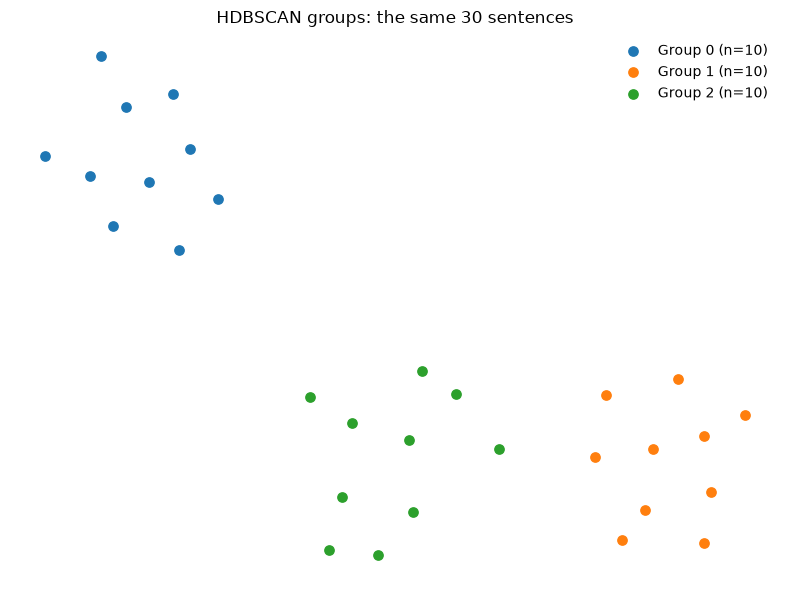

In [ ]:
map_coordinates = display_coordinates(embeddings)
plot_groups(map_coordinates, clusters, title="HDBSCAN groups: the same 30 sentences")

**_Note:_** This map is a display of assignments fitted in 10D. Its gaps and orientation are not precise measurements of topic differences. No reference categories were supplied to the model.

## 7. Compare with your manual clustering

Compare sentences' cluster memberships with your original solution for Exercise 3.
A different number of groups is an invitation to examine the grouping rule, not evidence that the computer is right.

In [ ]:
# add cluster assignments to the sentences data frame
sentences["cluster_group"] = clusters
sentences["cluster_group"].value_counts().sort_index()

In [45]:
# TODO: specify the IDs of the sentences you manually grouped into a cluster
my_cluster_ids = [] # e.g., "s01", "s03", etc.

In [46]:
subset = sentences.id.isin(my_cluster_ids)
sentences[subset]

,id,text


Inspect another group by changing `group_number`. Find a sentence that fits your interpretation and one that might fit a different group.